# Correlation of attributes with the labels

How strongly is each attribute associated with the three labels
(`SCREENING_3M_FLAG`, `SCREENING_6M_FLAG`, `SCREENING_12M_FLAG`)?

**Data:** the cleaned, prepared dataset `data/Rakhaton2026_prepared.csv` (all 1,344,556 invitations), built by
`preprocessing/pipeline.py`. It holds the original attributes plus the engineered ones (history `H_*`,
spatial `SPATIAL_*`, dates, flags). The `LIN_*` columns are only linear-model re-encodings of other columns
(dummies, median-filled copies), so they are left out.

**Measures**
- **Numeric and flag attributes:** Spearman rank correlation with each label, and Pearson in the table.
  Labels are 0/1, so Pearson is the point-biserial correlation. Spearman is robust to the long-tailed counts.
- **Categorical attributes:** Cramér's V (0 = no association, 1 = perfect). It has no sign.
- Attributes with missing values (e.g. `MONTHS_SINCE_LAST_SCREEN` exists only for previously screened women;
  history features only after an earlier invitation) are correlated on the rows where they are present.
  The `coverage` column shows that share. Read low-coverage correlations as "within that subgroup".

Correlation is not importance. Correlated attributes share the same signal (e.g. `INVITATION_SEQUENCE` vs
`PRIOR_INVITATION_COUNT`), and non-monotonic effects can show near-zero correlation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency


pd.set_option("display.max_rows", 200)
INK2, GRID = "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left",
})

LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
SHORT = {l: l.split("_")[1] for l in LABELS}  # 3M / 6M / 12M
CATEGORICAL = ["AGE_BAND", "VZP_TERRITORIAL_AREA", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]
NOT_ATTRIBUTES = {"INVITATION_ID", "PERSON_ID", "INVITATION_DATE", *LABELS}

df = pd.read_csv(Path("../data/Rakhaton2026_prepared.csv"), dtype={"INVITATION_ID": str, "PERSON_ID": str},
                 keep_default_na=False, na_values=[""])
numeric = [c for c in df.columns
           if c not in NOT_ATTRIBUTES | set(CATEGORICAL) and not c.startswith("LIN_")]
print(f"{len(df):,} invitations | {len(numeric)} numeric/flag attributes | {len(CATEGORICAL)} categorical")
print("Label rates:", {SHORT[l]: f"{df[l].mean():.1%}" for l in LABELS})

1,344,556 invitations | 60 numeric/flag attributes | 4 categorical
Label rates: {'3M': '7.1%', '6M': '12.5%', '12M': '19.3%'}


## 1. Numeric and flag attributes

In [2]:
ORIGINAL = set(pd.read_csv("../data/Rakhaton2026.csv", nrows=0).columns)


def origin(col):
    if col.startswith("H_"):
        return "history"
    if col.startswith("SPATIAL_"):
        return "spatial"
    return "original" if col in ORIGINAL else "engineered"


rows = []
for col in numeric:
    present = df[col].notna()
    x = df.loc[present, col]
    row = {"attribute": col, "origin": origin(col), "coverage": present.mean()}
    for l in LABELS:
        y = df.loc[present, l]
        row[f"spearman {SHORT[l]}"] = x.corr(y, method="spearman")
        row[f"pearson {SHORT[l]}"] = x.corr(y)
    rows.append(row)

corr = (pd.DataFrame(rows).set_index("attribute")
        .sort_values("spearman 12M", key=abs, ascending=False))
fmt = {c: "{:+.3f}" for c in corr.columns if c.startswith(("spearman", "pearson"))} | {"coverage": "{:.1%}"}
corr.style.format(fmt).background_gradient(
    subset=[c for c in corr.columns if c.startswith("spearman")], cmap="RdBu", vmin=-0.4, vmax=0.4)

,origin,coverage,spearman 3M,pearson 3M,spearman 6M,pearson 6M,spearman 12M,pearson 12M
attribute,,,,,,,,
PRIOR_INVITATION_COUNT,original,100.0%,-0.250,-0.240,-0.327,-0.315,-0.390,-0.377
INVITATION_SEQUENCE,original,100.0%,-0.245,-0.230,-0.322,-0.303,-0.386,-0.366
FIRST_INVITATION,original,100.0%,+0.248,+0.248,+0.316,+0.316,+0.360,+0.360
GYN_PREVENTION_24M_CNT,original,100.0%,+0.243,+0.238,+0.293,+0.284,+0.332,+0.320
PREVENTION_TYPES,engineered,100.0%,+0.216,+0.216,+0.267,+0.268,+0.308,+0.309
PREVENTION_TOTAL,engineered,100.0%,+0.213,+0.211,+0.261,+0.254,+0.299,+0.288
H_NONRESP_STREAK,history,100.0%,-0.168,-0.157,-0.220,-0.206,-0.256,-0.241
H_N_PREV_KNOWN,history,100.0%,-0.168,-0.157,-0.219,-0.206,-0.255,-0.241
OTHER_SCREENING_36M_CNT,original,100.0%,+0.184,+0.154,+0.222,+0.183,+0.254,+0.207


### Heatmap: Spearman correlation with each label

Sorted by the strength of the correlation with the 12M label. Blue = more likely to be screened, red = less likely.
The bracket after a name shows its origin and, if below 100%, its coverage.

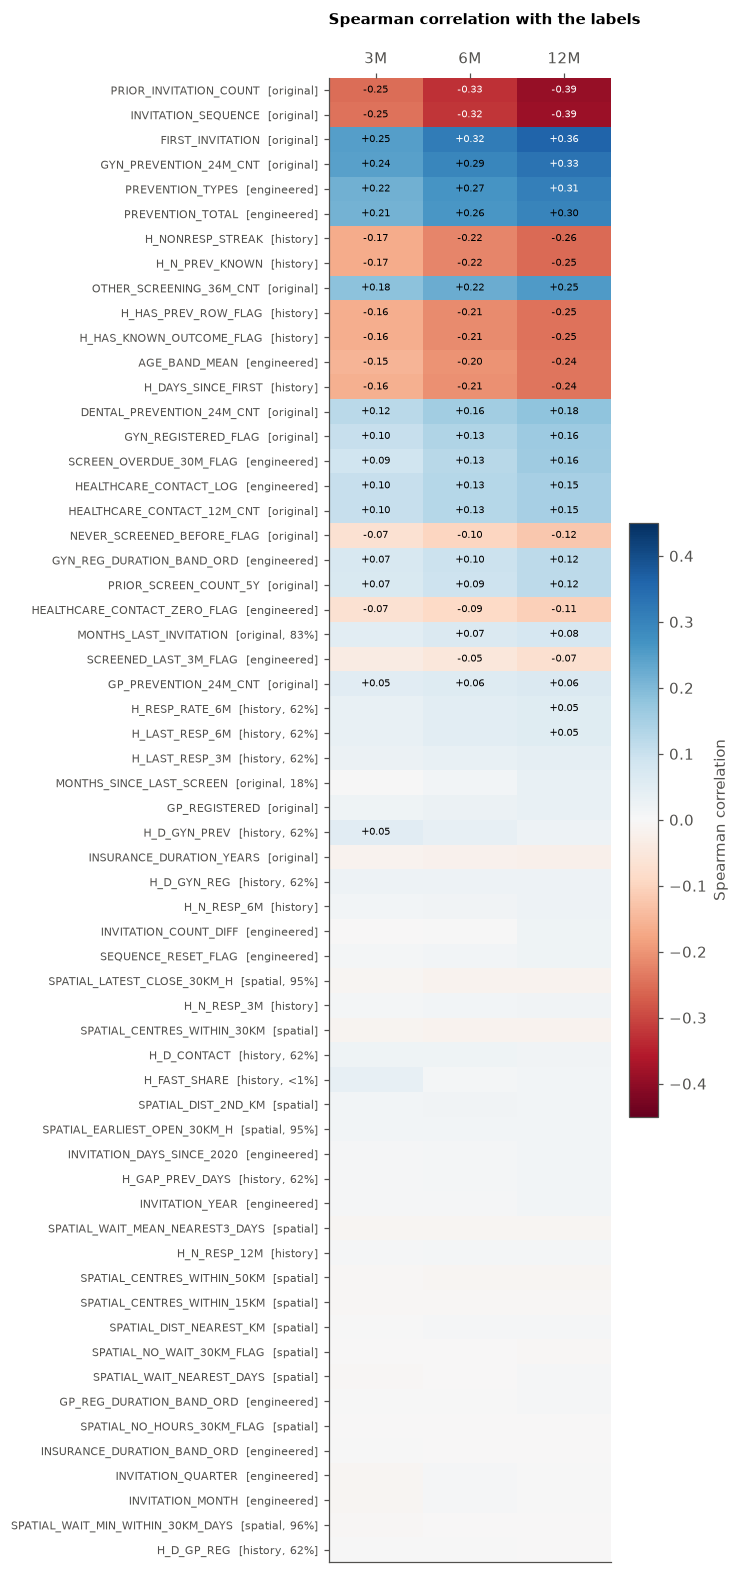

In [3]:
sp = corr[[f"spearman {SHORT[l]}" for l in LABELS]]
names = [f"{a}  [{o}{'' if c > 0.995 else ', <1%' if c < 0.01 else f', {c:.0%}'}]" for a, o, c in zip(corr.index, corr.origin, corr.coverage,
                                                                                    strict=True)]
fig, ax = plt.subplots(figsize=(6.5, 0.22 * len(sp) + 1.2))
im = ax.imshow(sp.to_numpy(), cmap="RdBu", vmin=-0.45, vmax=0.45, aspect="auto")
ax.set_xticks(range(3), [SHORT[l] for l in LABELS])
ax.xaxis.tick_top()
ax.set_yticks(range(len(sp)), names, fontsize=7)
for i in range(sp.shape[0]):
    for j in range(3):
        v = sp.iat[i, j]
        if abs(v) >= 0.05:
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(v) > 0.3 else "black")
fig.colorbar(im, ax=ax, shrink=0.4, label="Spearman correlation")
ax.set_title("Spearman correlation with the labels\n", loc="left")
plt.tight_layout(); plt.show()

## 2. Categorical attributes

Cramér's V between each categorical attribute and each label. For context, the table also shows how
many categories each has and how far apart their 12M response rates are.

In [4]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


cat_rows = []
for col in CATEGORICAL:
    x = df[col].fillna("not registered")  # missing band = not registered
    rate = df.groupby(x)["SCREENING_12M_FLAG"].mean()
    cat_rows.append({"attribute": col, "categories": x.nunique(),
                     **{f"Cramér's V {SHORT[l]}": cramers_v(x, df[l]) for l in LABELS},
                     "12M rate: lowest": f"{rate.min():.1%} ({rate.idxmin()})",
                     "12M rate: highest": f"{rate.max():.1%} ({rate.idxmax()})"})
cat = pd.DataFrame(cat_rows).set_index("attribute").sort_values("Cramér's V 12M", ascending=False)
cat.style.format({c: "{:.3f}" for c in cat.columns if c.startswith("Cramér")})

,categories,Cramér's V 3M,Cramér's V 6M,Cramér's V 12M,12M rate: lowest,12M rate: highest
attribute,,,,,,
AGE_BAND,7,0.190,0.247,0.287,10.0% (70-74),56.8% (40-44)
GYN_REG_DURATION_BAND,4,0.109,0.141,0.171,6.9% (not registered),29.8% (<2)
VZP_TERRITORIAL_AREA,75,0.046,0.047,0.050,12.8% (KARVINÁ),23.8% (PELHŘIMOV)
GP_REG_DURATION_BAND,4,0.021,0.028,0.034,8.4% (not registered),20.4% (<2)


## 3. How the labels relate to each other

The labels are nested (3M ⇒ 6M ⇒ 12M), so they are strongly correlated. An attribute that correlates more with
3M than with 12M is linked to *fast* response.

In [5]:
df[LABELS].rename(columns=SHORT).corr().style.format("{:.2f}")

,3M,6M,12M
3M,1.00,0.73,0.57
6M,0.73,1.00,0.77
12M,0.57,0.77,1.00


## 4. Takeaways

**1. Invitation history and preventive behaviour carry the strongest signal** (Spearman, 12M):
- Invitation history: `PRIOR_INVITATION_COUNT` −0.39, `INVITATION_SEQUENCE` −0.39, `FIRST_INVITATION` +0.36. Each
  ignored invitation makes the next response less likely.
- Preventive behaviour: `GYN_PREVENTION_24M_CNT` +0.33, `OTHER_SCREENING_36M_CNT` +0.25,
  `DENTAL_PREVENTION_24M_CNT` +0.18. Women who already take part in prevention respond.
- Age: `AGE_BAND` has Cramér's V 0.29 (response falls from 56.8% at 40–44 to 10.0% at 70–74).
- Gynaecologist registration matters (V 0.17, ρ +0.16); GP registration hardly does (V 0.03, ρ +0.03).

**2. Correlation underrates the most important model feature.** `MONTHS_SINCE_LAST_SCREEN` has Spearman only
+0.03 (Pearson +0.18; present for the 18% of women screened before), yet it is the top feature in the models.
Its effect is non-monotonic: women screened 0–3 months ago almost never respond, response peaks around 36 months and
then falls. A single correlation coefficient cannot capture that shape.

**3. Most engineered attributes repeat what the originals already say.** `H_NONRESP_STREAK`, `H_N_PREV_KNOWN` and
`H_DAYS_SINCE_FIRST` mirror the invitation count. `PREVENTION_TYPES` / `PREVENTION_TOTAL` mirror the prevention
counts. This matches the modelling result that the extra features add only +0.001 ROC AUC.

**4. Location, distance and timing are barely related to the labels.** All spatial attributes have |ρ| ≤ 0.02,
`VZP_TERRITORIAL_AREA` has V 0.05, and the date attributes (year, month, quarter) are ≈ 0.

**5. Signs are consistent across horizons.** Nearly every attribute points the same way for 3M, 6M and 12M, with
magnitudes growing towards 12M. No attribute stands out as specifically predicting *fast* response.